# 02 · Minute bars

One-minute OHLCV bars for every ticker since 2003, including pre- and post-market (about
7.6 billion rows, 82 GB). One file per trading day, sorted by ticker, so one ticker's full
history loads in a few seconds.

1. one day up close: sessions and resampling
2. intraday patterns: volume and volatility through the day
3. early closes and extended-hours trading
4. overnight vs intraday returns, and realized volatility from minute data

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from massive_subspace_stream import Store
from subspace_probe import style, timed

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
store = Store()
NY = "America/New_York"

## 1 · One day up close

The latest stored day of SPY, all sessions. Pre-market starts at 04:00 and post-market runs
until 20:00 New York time. Timestamps are stored in UTC; convert for display.

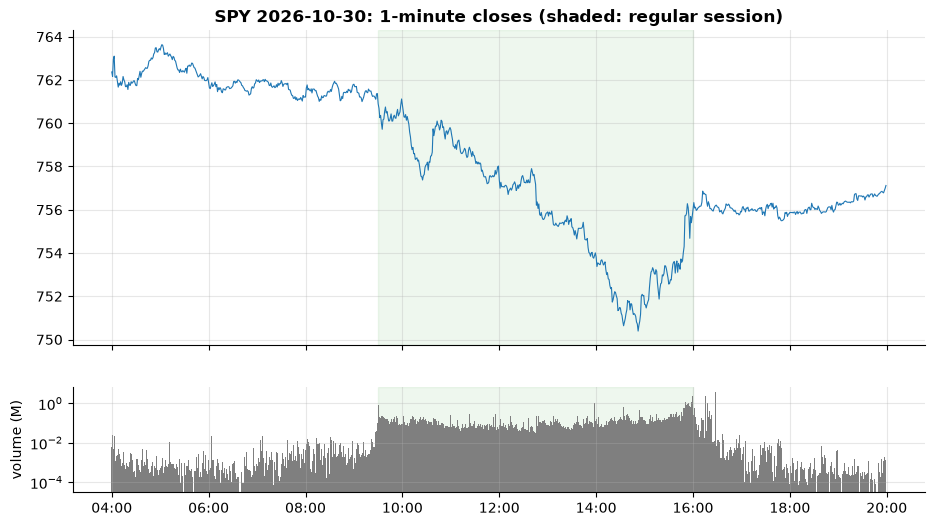

In [2]:
day = store.coverage().filter(pl.col("dataset") == "bars_minute")["last"].item()
spy = store.bars("SPY", start=day, end=day, freq="1min").with_columns(pl.col("timestamp").dt.convert_time_zone(NY).alias("t"))
sess = store.sessions(day).with_columns(pl.col("market_open", "market_close").dt.convert_time_zone(NY)).row(0, named=True)

fig, (ax, axv) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(spy["t"], spy["close"], lw=0.8)
for a in (ax, axv):
    a.axvspan(sess["market_open"], sess["market_close"], color="tab:green", alpha=0.08)
ax.set_title(f"SPY {day}: 1-minute closes (shaded: regular session)")
axv.bar(spy["t"], spy["volume"] / 1e6, width=1 / 1440, color="tab:gray")
axv.set_ylabel("volume (M)")
axv.set_yscale("log")
axv.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=sess["market_open"].tzinfo));

Pre- and post-market volume is a small fraction of the day, and the bars are sparse (many
minutes have no trade at all, so there is no bar). Volume jumps at the 09:30 open and builds
into the 16:00 close (the closing auction itself is not in minute bars; see the caveat below).

**Resampling.** The store keeps 1-minute bars; other bar sizes are a `group_by_dynamic` away:

In [3]:
def resample(bars: pl.DataFrame, every: str) -> pl.DataFrame:
    """Aggregate 1-minute bars into larger bars per ticker (e.g. '5m', '30m', '1h')."""
    return (
        bars.sort("ticker", "timestamp")
        .group_by_dynamic("timestamp", every=every, group_by="ticker", label="left")
        .agg(
            pl.col("open").first(), pl.col("high").max(), pl.col("low").min(), pl.col("close").last(),
            pl.col("volume").sum(), pl.col("transactions").sum(),
        )
    )

regular = store.bars("SPY", start=day, end=day, freq="1min", session="regular")
resample(regular, "30m").with_columns(pl.col("timestamp").dt.convert_time_zone(NY).dt.strftime("%H:%M").alias("ny_time")).select(
    "ny_time", "open", "high", "low", "close", (pl.col("volume") / 1e6).round(2).alias("volume_m")
)

ny_time,open,high,low,close,volume_m
str,f64,f64,f64,f64,f64
"""09:30""",761.38,761.46,759.44,761.121,5.46
"""10:00""",761.14,761.28,757.28,758.06,4.58
"""10:30""",758.06,760.4,757.75,759.8,3.27
"""11:00""",759.82,760.03,758.41,758.51,2.61
"""11:30""",758.51,758.54,757.12,758.02,2.46
"""12:00""",758.01,758.01,756.66,757.58,2.42
"""12:30""",757.56,758.01,755.31,755.86,2.64
"""13:00""",755.85,756.05,755.04,755.59,2.79
"""13:30""",755.58,755.64,753.7,754.005,4.38


## 2 · Intraday patterns

Averaging over a year of regular sessions shows the classic shapes: volume is **U-shaped**
(heavy at the open and very heavy into the close), and volatility is highest in the first
minutes and decays through the day.

SPY, AAPL, IWM minute bars for 2024: 0.46 s


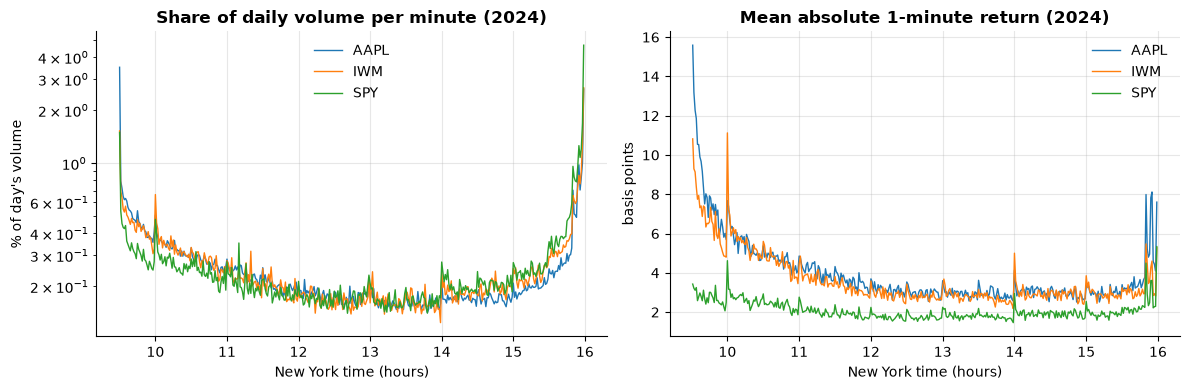

In [4]:
with timed("SPY, AAPL, IWM minute bars for 2024"):
    m24 = store.bars(["SPY", "AAPL", "IWM"], start="2024-01-01", end="2024-12-31", freq="1min", session="regular")

prof = (
    m24.with_columns(
        pl.col("timestamp").dt.convert_time_zone(NY).dt.time().alias("tod"),
        (pl.col("volume") / pl.col("volume").sum().over("ticker", "date")).alias("vol_share"),
        pl.col("close").log().diff().over("ticker", "date").abs().alias("abs_ret"),
    )
    .group_by("ticker", "tod")
    .agg(pl.col("vol_share").mean(), (pl.col("abs_ret").mean() * 1e4).alias("abs_ret_bp"), pl.len().alias("days"))
    .filter(pl.col("days") > 200)  # drop minutes that only exist on some days (early closes)
    .sort("ticker", "tod")
)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for t, g in prof.group_by("ticker", maintain_order=True):
    x = [v.hour + v.minute / 60 for v in g["tod"]]
    a1.plot(x, g["vol_share"] * 100, label=t[0], lw=1)
    a2.plot(x, g["abs_ret_bp"], label=t[0], lw=1)
a1.set_title("Share of daily volume per minute (2024)")
a1.set_ylabel("% of day's volume")
a1.set_yscale("log")
a2.set_title("Mean absolute 1-minute return (2024)")
a2.set_ylabel("basis points")
for a in (a1, a2):
    a.set_xlabel("New York time (hours)")
    a.legend()
fig.tight_layout()

In [5]:
close_share = prof.filter(pl.col("tod") == pl.time(15, 59)).select("ticker", (pl.col("vol_share") * 100).round(1).alias("pct_in_last_minute"))
close_share

ticker,pct_in_last_minute
str,f64
"""AAPL""",2.6
"""IWM""",2.7
"""SPY""",4.7


The last regular minute carries 2–5% of the day's volume, more than any minute in the middle
of the day.

### Caveat: minute bars leave out the closing auction

The closing auction (one huge print at 16:00) is **in the daily bar but not in the minute
bars**. Compare daily volume with the sum of the minute bars:

In [6]:
rows = []
for year in (2005, 2015, 2024, 2026):
    start, end = f"{year}-03-01", f"{year}-03-31"
    minute = store.bars(["AAPL", "SPY", "IWM"], start=start, end=end, freq="1min").group_by("ticker", "date").agg(pl.col("volume").sum().alias("minute_sum"))
    daily = store.bars(["AAPL", "SPY", "IWM"], start=start, end=end).select("ticker", "date", pl.col("volume").alias("daily"))
    rows.append(daily.join(minute, on=["ticker", "date"]).group_by("ticker").agg(
        ((1 - pl.col("minute_sum") / pl.col("daily")) * 100).mean().round(1).alias(f"{year}")))
gap = rows[0]
for r in rows[1:]:
    gap = gap.join(r, on="ticker")
print("% of daily volume missing from the minute bars (March of each year):")
gap.sort("ticker")

% of daily volume missing from the minute bars (March of each year):


ticker,2005,2015,2024,2026
str,f64,f64,f64,f64
"""AAPL""",2.8,5.9,14.7,27.9
"""IWM""",2.0,4.2,3.5,2.3
"""SPY""",3.6,2.8,2.9,2.2


Notebook 03 checks this with trade-level data for 2019-06-28: there, the gap is exactly the
closing auction print. For AAPL the gap has grown to 20–30% on every day in 2026, which is
likely more than the auction alone; recent days have not been checked trade by trade (that
needs a 3–4 GB trades download per day). In practice:
- use **daily bars** for daily volume, dollar volume and the official close;
- use minute bars for intraday shape, and treat 16:00 volume as incomplete.

## 3 · Early closes and extended hours

`session="regular"` uses the NYSE calendar, so half days are handled without special cases.
The day after Thanksgiving 2024 closed at 13:00:

In [7]:
for d in ("2024-11-27", "2024-11-29"):
    b = store.bars("SPY", start=d, end=d, freq="1min", session="regular")
    last = b["timestamp"].max().astimezone(__import__("zoneinfo").ZoneInfo(NY))
    print(f"{d}: {b.height} regular-session bars, last bar starts {last:%H:%M} New York time")

2024-11-27: 390 regular-session bars, last bar starts 15:59 New York time
2024-11-29: 210 regular-session bars, last bar starts 12:59 New York time


**Extended-hours trading has grown.** Share of AAPL's volume traded outside regular hours,
by year, from its full minute history (about 3.8M bars):

AAPL full minute history: 3.76 s


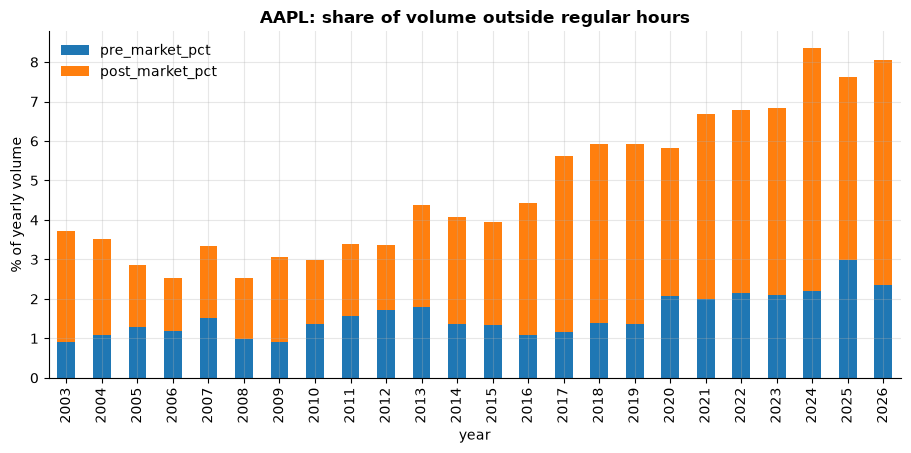

In [8]:
with timed("AAPL full minute history"):
    aapl = store.bars("AAPL", start="2003-09-10", freq="1min")
reg = store.bars("AAPL", start="2003-09-10", freq="1min", session="regular", columns=["timestamp"]).with_columns(pl.lit(True).alias("regular"))
ext = (
    aapl.join(reg, on="timestamp", how="left")
    .with_columns(
        pl.col("regular").fill_null(False),
        pl.when(pl.col("timestamp").dt.convert_time_zone(NY).dt.hour() < 12).then(pl.lit("pre")).otherwise(pl.lit("post")).alias("half"),
    )
    .group_by(pl.col("date").dt.year().alias("year"))
    .agg(
        (pl.col("volume").filter(~pl.col("regular") & (pl.col("half") == "pre")).sum() / pl.col("volume").sum() * 100).alias("pre_market_pct"),
        (pl.col("volume").filter(~pl.col("regular") & (pl.col("half") == "post")).sum() / pl.col("volume").sum() * 100).alias("post_market_pct"),
    )
    .sort("year")
)
ax = ext.to_pandas().set_index("year").plot.bar(stacked=True, title="AAPL: share of volume outside regular hours")
ax.set_ylabel("% of yearly volume");

## 4 · Overnight vs intraday returns, realized volatility

Split each SPY day into **overnight** (previous close to today's open) and **intraday** (open
to close), using the regular-session open and close from minute bars and `adjust="all"` so
dividends and splits don't create fake jumps.

SPY full minute history, regular session, total-return adjusted: 3.73 s


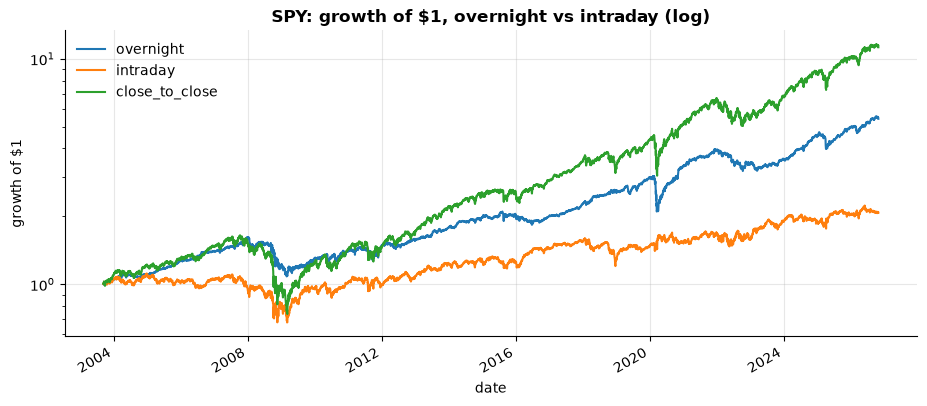

In [9]:
with timed("SPY full minute history, regular session, total-return adjusted"):
    spy_all = store.bars("SPY", start="2003-09-10", freq="1min", session="regular", adjust="all")

daily = (
    spy_all.group_by("date")
    .agg(pl.col("open").first(), pl.col("close").last())
    .sort("date")
    .with_columns(
        (pl.col("open") / pl.col("close").shift(1)).log().alias("overnight"),
        (pl.col("close") / pl.col("open")).log().alias("intraday"),
    )
    .drop_nulls()
)
cum = daily.select("date", pl.col("overnight").cum_sum().exp(), pl.col("intraday").cum_sum().exp(),
                   (pl.col("overnight") + pl.col("intraday")).cum_sum().exp().alias("close_to_close"))
ax = cum.to_pandas().set_index("date").plot(logy=True, title="SPY: growth of $1, overnight vs intraday (log)")
ax.set_ylabel("growth of $1");

Since 2003, a large part of SPY's total return was earned overnight, while holding only during
regular hours earned much less. This well-known pattern is a good example of a question that
needs intraday data: daily bars alone cannot separate the two.

**Realized volatility.** Summing squared 5-minute returns within each day gives a daily
volatility estimate that reacts much faster than a rolling window of daily returns:

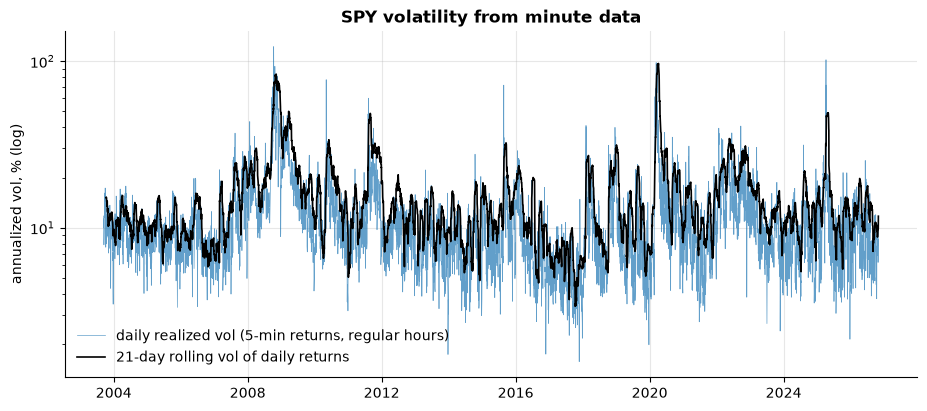

In [10]:
rv = (
    resample(spy_all, "5m")
    .with_columns(pl.col("timestamp").dt.convert_time_zone(NY).dt.date().alias("date"))
    .with_columns(pl.col("close").log().diff().over("date").alias("r"))
    .group_by("date")
    .agg((pl.col("r").pow(2).sum() * 252).sqrt().alias("realized_vol"))
    .sort("date")
)
d = daily.with_columns((pl.col("overnight") + pl.col("intraday")).alias("cc")).with_columns(
    (pl.col("cc").rolling_std(21) * np.sqrt(252)).alias("rolling_21d_vol")
)
fig, ax = plt.subplots()
ax.plot(rv["date"], rv["realized_vol"] * 100, lw=0.5, alpha=0.7, label="daily realized vol (5-min returns, regular hours)")
ax.plot(d["date"], d["rolling_21d_vol"] * 100, lw=1.2, color="black", label="21-day rolling vol of daily returns")
ax.set_yscale("log")
ax.set_ylabel("annualized vol, % (log)")
ax.set_title("SPY volatility from minute data")
ax.legend();

## Takeaways
- `freq="1min"` with `session=` handles exchange hours and half days; resample with
  `group_by_dynamic` for other bar sizes.
- Single-ticker histories load in seconds; for many tickers use `lazy=True` and aggregate
  before collecting.
- Intraday structure (U-shaped volume, open/close effects, overnight returns) is strong and
  only visible at this resolution.

Next: **03 · Trades and quotes**.